In [17]:
import os

import pandas as pd
import numpy as np
from ot import sliced_wasserstein_distance
import random
import itertools
import matplotlib.pyplot as plt
import seaborn as sns
from cluster_weather_years.functions import standardize_df
from cluster_weather_years.constants import (
    BASE_OUTPUT,
    MODELS,
    HYDROLOGICAL_YEARS,
    # NUM_CLUSTERS,
    COUNTRIES,
)
from sa_settings import MATCH_COUNTRIES, NUM_CLUSTERS

In [ ]:
# Config
NUM_CLUSTERS = 5  # hardcode

# RUN_ID = "NL_20251003_1321"  # NL, 30 years
RUN_ID = "NL_20251001_1220"  # NL, 5 years
RUN_ID_alternative = "BE_20251001_1623"  # BE
# NUM_CLUSTERS = 5  # hardcode

seed = 42
random.seed(seed)

# 1. Build dataframes

In [19]:
# build df
DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
)
SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")

vars_to_match = (
    [f"{country}_OFF_prod" for country in MATCH_COUNTRIES]
    + [f"{country}_ON_prod" for country in MATCH_COUNTRIES]
    + [f"{country}_SOLAR_prod" for country in MATCH_COUNTRIES]
    + [f"{country}_Demand" for country in MATCH_COUNTRIES]
)

vars_to_standardize = df_daily.columns[3:-1].values
df_std = standardize_df(df_daily, vars_to_standardize)

In [56]:
df_selections = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID}/results_grid.csv"), index_col=0
)
# df_sel_wasserstein = df_selections.query("optimized_metric == 'wasserstein_score'").sort_values("best_score", ascending=True)
df_sel_multi_country = df_selections.query(
    "optimized_metric == 'wasserstein_score'"
).sort_values("best_score", ascending=True)

df_selections_alternative = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_alternative}/results_grid.csv"),
    index_col=0,
)
df_sel_alternative = df_selections_alternative.query(
    "optimized_metric == 'wasserstein_score'"
).sort_values("best_score", ascending=True)

df_sel_multi_country = df_sel_multi_country.sample(
    len(df_sel_alternative), random_state=seed
)
# df_selections_old = pd.read_csv(
#     os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID_old}/results_grid.csv"), index_col=0
# )
# df_sel_combined = df_selections_old.query(
#     "optimized_metric == 'combined_score'"
# ).sort_values("best_score", ascending=True)
# df_sel_anderson = df_selections_old.query("optimized_metric == 'ad_total'").sort_values(
#     "best_score", ascending=True
# )

centroids_k_medoids = pd.read_csv(
    os.path.join(BASE_OUTPUT, "centroids/centroid_years_cf.csv"), index_col=0
)
centroids_k_medoids_sel = centroids_k_medoids[["model", "Hydrological_year"]].values

centroids_k_medoids_load = pd.read_csv(
    os.path.join(BASE_OUTPUT, "centroids/centroid_years_load.csv"), index_col=0
)
centroids_k_medoids_load_sel = centroids_k_medoids_load[
    ["model", "Hydrological_year"]
].values


In [57]:
centroids_k_medoids_sel

array([['cmcc_cm2_sr5', 2032],
       ['mpi_esm1_2_hr', 2033],
       ['cmcc_cm2_sr5', 2038],
       ['cmcc_cm2_sr5', 2040],
       ['cmcc_cm2_sr5', 2037]], dtype=object)

In [38]:
centroids_k_medoids_load

,model,Hydrological_year,NL_OFF_prod,NL_ON_prod,NL_SOLAR_prod,NL_Demand,NL_Residual_load,DE_OFF_prod,DE_ON_prod,DE_SOLAR_prod,...,BE_SOLAR_prod,BE_Demand,BE_Residual_load,FR_OFF_prod,FR_ON_prod,FR_SOLAR_prod,FR_Demand,FR_Residual_load,Calendar_year,count
cluster_id,,,,,,,,,,,,,,,,,,,,,
0,mpi_esm1_2_hr,2033,4.746606,10.157553,-1.105430,-1.044712,4553.840083,6.878788,12.103014,1.029267,...,-1.899701,-0.757543,-135.825912,9.887847,9.370247,2.281565,-0.600611,241.645302,0.197089,52
1,mpi_esm1_2_hr,2027,0.779888,-2.231308,-0.406426,0.809580,-916.635053,3.581814,-2.622177,2.508615,...,-0.951430,0.837111,24.141846,-4.572644,-3.468916,0.261229,0.816275,-106.996366,-0.098485,26
2,awi_cm_1_1_mr,2034,1.537172,1.977881,0.583225,-0.186832,1478.621641,4.350158,4.634696,-0.050247,...,0.059781,-0.678522,2.393661,-5.552868,2.353198,0.130221,-0.767413,-46.927056,0.246369,32
3,mri_esm2_0,2020,-8.287280,-10.138874,1.275325,-0.460948,-4733.512019,-9.111827,-9.276635,4.635415,...,4.397420,-0.422326,69.373235,-4.467664,-3.823590,5.559871,-0.356533,5.699208,-0.443542,25
4,mri_esm2_0,2041,-2.848798,-2.638691,-0.183302,0.507797,-2419.089850,-0.714246,5.513015,1.907241,...,0.465971,0.296012,73.648107,0.212857,-2.920331,2.068591,0.281199,10.507577,0.591324,39


In [39]:
def build_df_random(df_daily, num_random=NUM_CLUSTERS):
    # build random selection df, based on random draw of NUM_CLUSTER years for comparison
    model_years = list(itertools.product(MODELS, HYDROLOGICAL_YEARS))
    random_models_years = random.sample(model_years, k=num_random)

    frames_random = []
    for model_random, year_random in random_models_years:
        df_random = df_daily.query(
            f"model == '{model_random}' and Hydrological_year == {year_random}"
        )
        frames_random.append(df_random)
    return pd.concat(frames_random, ignore_index=True)


def build_df_centroids(df_daily, selected, mode="Hydrological_year"):
    """
    Build df with daily data of selected years
    """
    frames_centroids = []
    for i, (model, year) in enumerate(selected):
        # model_centroid, year_centroid = row["model"], row["Date"]
        if mode == "Hydrological_year":
            df_centroid = df_daily.query(
                f"model == '{model}' and Hydrological_year == {year}"
            )
        elif mode == "Calendar_year":
            df_centroid = df_daily.query(
                f"model == '{model}' and Calendar_year == {year}"
            )
        frames_centroids.append(df_centroid)

    return pd.concat(frames_centroids, ignore_index=True)


In [40]:
def build_df_random_large(df_daily, size):
    """
    Build a dataframe with random model-year combinations of arbritary size. To set a benchmark
    """
    model_years = list(itertools.product(MODELS, HYDROLOGICAL_YEARS))
    random_models_years = random.sample(model_years, k=size)

    frames_random = []
    for model_random, year_random in random_models_years:
        df_random = df_daily.query(
            f"model == '{model_random}' and Hydrological_year == {year_random}"
        )
        frames_random.append(df_random)
    return pd.concat(frames_random, ignore_index=True)


# df_random_large = build_df_random_large(df_daily, int(50))

# 2. Perform comparison

In [23]:
# just simple ECDF plots for visual inspection
def ecdf_comparison(df_daily, df_centroids, df_random, columns):
    fig, axs = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

    for i, col in enumerate(columns):
        ax = axs.flat[i]
        sns.ecdfplot(df_centroids, x=col, label="Centroid years", ax=ax)
        sns.ecdfplot(df_random, x=col, label="Randomly sampled years", ax=ax)
        sns.ecdfplot(df_daily, x=col, label="Full climatology", ax=ax)
        ax.set_title(col)
        ax.set_ylim(0, 1.02)
        ax.legend(loc="lower right")

    # Hide any unused axes (in case columns < 4)
    for j in range(len(columns), 4):
        axs.flat[j].axis("off")

In [24]:
def _qq_probabilities_and_weights():
    dense = np.linspace(0.005, 0.05, 100, endpoint=False)
    coarse = np.linspace(0.05, 0.995, 96)
    probs = np.concatenate([dense, coarse])
    w = np.empty_like(probs)
    w[1:-1] = (probs[2:] - probs[:-2]) / 2
    w[0] = (probs[1] - probs[0]) / 2
    w[-1] = (probs[-1] - probs[-2]) / 2
    return probs, w


def qq_compute_metrics(df_daily, datasets, columns):
    """
    Compute QQ-based metrics for one or many datasets vs the full df_daily.

    Parameters
    - df_daily: reference dataframe (full climatology)
    - datasets: dict[str, pd.DataFrame], e.g. {"Centroid": df_centroids, "Random": df_random}
    - columns: list[str] variables to analyze

    Returns
    - pd.DataFrame with rows per (dataset, variable) and columns [MAE, RMSE, MaxAbs]
    """
    probs, w = _qq_probabilities_and_weights()
    rows = []
    for col in columns:
        q_full = df_daily[col].quantile(probs)
        median_full = df_daily[col].quantile(0.5)
        x = q_full.values
        for name, df in datasets.items():
            q_sub = df[col].quantile(probs)
            diff = (q_sub - q_full).values
            rows.append(
                {
                    "dataset": name,
                    "variable": col,
                    "MAE": float(np.average(np.abs(diff), weights=w)),
                    "RMSE": float(np.sqrt(np.average(diff**2, weights=w))),
                    "MaxAbs": float(np.max(np.abs(diff))),
                    "Median of VAR": float(median_full),
                    "x_min": float(np.nanmin(x)),
                    "x_max": float(np.nanmax(x)),
                }
            )
    return pd.DataFrame(rows)


def qq_plot(df_daily, datasets, columns):
    """
    Plot QQ curves and quantile differences for provided datasets vs full df.

    Parameters
    - df_daily: reference dataframe (full climatology)
    - datasets: dict[str, pd.DataFrame], e.g. {"Centroid": df_centroids, "Random": df_random}
    - columns: list[str]
    """
    probs, _ = _qq_probabilities_and_weights()
    fig_qq, axs_qq = plt.subplots(2, 2, figsize=(12, 10))
    fig_diff, axs_diff = plt.subplots(2, 2, figsize=(12, 10), sharey=False)

    for i, col in enumerate(columns):
        q_full = df_daily[col].quantile(probs)
        x = q_full.values

        # QQ plot
        axq = axs_qq.flat[i]
        for j, (name, df) in enumerate(datasets.items()):
            q_sub = df[col].quantile(probs)
            axq.plot(x, q_sub.values, label=name)
        lo, hi = np.nanmin(x), np.nanmax(x)
        axq.plot([lo, hi], [lo, hi], "k--", lw=1, label="y=x")
        axq.set_title(f"QQ: {col}")
        axq.set_xlabel("Full climatology value")
        axq.set_ylabel("Subset value")
        axq.legend(loc="best")

        # Differences
        axd = axs_diff.flat[i]
        for j, (name, df) in enumerate(datasets.items()):
            q_sub = df[col].quantile(probs)
            diff = (q_sub - q_full).values
            axd.plot(probs, diff, color=f"C{j}", label=f"{name} - Full")
            axd.plot(probs, np.abs(diff), color=f"C{j}", ls="--")
        axd.axhline(0.0, color="k", lw=1, ls="--")
        axd.set_title(f"QQ-differences: {col}")
        axd.set_xlabel("Quantile")
        axd.set_ylabel("Δ value")
        axd.legend(loc="best")

    for j in range(len(columns), 4):
        axs_qq.flat[j].axis("off")
        axs_diff.flat[j].axis("off")

    fig_qq.tight_layout()
    fig_diff.tight_layout()

    return fig_qq, fig_diff


In [25]:
def aggregate_qq_metrics(df_daily, centroid_runs, df_random, columns):
    """
    Compute QQ metrics for many centroid runs against the same df_random baseline.

    Parameters
    - df_daily: reference dataframe
    - centroid_runs: dict[str, pd.DataFrame] mapping run name -> df_centroids
    - df_random: baseline random dataframe
    - columns: list[str]

    Returns
    - pd.DataFrame with columns [run, dataset, variable, MAE, RMSE, MaxAbs, x_min, x_max]
      where dataset is in {"Centroid", "Random"}
    """
    all_rows = []
    for run_name, dfc in centroid_runs.items():
        m = qq_compute_metrics(
            df_daily, {"Centroid": dfc, "Random": df_random}, columns
        )
        m.insert(0, "run", run_name)
        all_rows.append(m)
    if not all_rows:
        return pd.DataFrame(
            columns=[
                "run",
                "dataset",
                "variable",
                "MAE",
                "RMSE",
                "MaxAbs",
                "x_min",
                "x_max",
            ]
        )
    return pd.concat(all_rows, ignore_index=True)


def qq_metric_deltas(metrics_df):
    """
    From a metrics dataframe (as returned by qq_compute_metrics or aggregate_qq_metrics),
    compute Centroid - Random deltas per run and variable.

    Returns
    - pd.DataFrame indexed by [run, variable] with columns [MAE_delta, RMSE_delta, MaxAbs_delta]
    """
    required_cols = {"dataset", "variable", "MAE", "RMSE", "MaxAbs"}
    missing = required_cols - set(metrics_df.columns)
    if missing:
        raise ValueError(f"metrics_df missing columns: {sorted(missing)}")
    if "run" not in metrics_df.columns:
        metrics_df = metrics_df.assign(run="__single__")

    piv = metrics_df.pivot_table(
        index=["run", "variable"],
        columns="dataset",
        values=["MAE", "RMSE", "MaxAbs"],
        aggfunc="first",
    )
    # Compute deltas: Centroid - Random
    out = pd.DataFrame(index=piv.index)
    for m in ["MAE", "RMSE", "MaxAbs"]:
        if (m, "Centroid") in piv.columns and (m, "Random") in piv.columns:
            out[f"{m}_delta"] = piv[(m, "Centroid")] - piv[(m, "Random")]
    return out.reset_index()


In [58]:
columns = vars_to_standardize.copy()

# Create datasets dictionary with all available selections from df_sel_combined
datasets = {}

for i in range(len(df_sel_multi_country)):
    datasets[f"Multi-country {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_multi_country.iloc[i]["selected"])
    )
    datasets[f"Random_N {i + 1}"] = build_df_random(df_daily, num_random=NUM_CLUSTERS)

for i in range(len(df_sel_alternative)):
    datasets[f"Alternative {i + 1}"] = build_df_centroids(
        df_daily, eval(df_sel_alternative.iloc[i]["selected"])
    )

datasets["K_medoids_cf"] = build_df_centroids(
    df_daily, centroids_k_medoids_sel, mode="Hydrological_year"
)

datasets["K_medoids_load"] = build_df_centroids(
    df_daily, centroids_k_medoids_load_sel, mode="Hydrological_year"
)


sizes = [
    5,
    10,
    25,
    50,
    90,
    120,
    150,
    174,
]  # 174 is full dataset, because of hydrological years!
for size in sizes:
    datasets[f"Large Random {size}"] = build_df_random_large(df_daily, size)
# datasets["Large Random"] = df_random_large


df_metrics = qq_compute_metrics(df_daily, datasets, columns)

In [59]:
# Add Multi RMSE column which is the average of RMSE for the specified variables
df_metrics_with_multi = df_metrics.copy()

# Calculate Multi RMSE for each dataset
multi_rmse_values = []
full_rmse_values = []
for dataset in df_metrics["dataset"].unique():
    dataset_metrics = df_metrics[df_metrics["dataset"] == dataset]
    country_rmse = []
    for country in COUNTRIES:
        multi_rmse_vars = [
            f"{country}_OFF_prod",
            f"{country}_ON_prod",
            f"{country}_SOLAR_prod",
            f"{country}_Demand",
        ]
        multi_rmse = dataset_metrics[dataset_metrics["variable"].isin(multi_rmse_vars)][
            "RMSE"
        ].mean()
        country_rmse.append(multi_rmse)
        multi_rmse_values.append(
            {
                "dataset": dataset,
                "variable": f"Multi RMSE {country}",
                "MAE": None,
                "RMSE": multi_rmse,
                "MaxAbs": None,
                "x_min": None,
                "x_max": None,
            }
        )
    full_rmse_values.append(
        {
            "dataset": dataset,
            "variable": "Full RMSE",
            "RMSE": np.array(country_rmse).mean(),
        }
    )


# Add Multi RMSE rows to the dataframe
multi_rmse_df = pd.DataFrame(multi_rmse_values)
df_metrics_with_multi = pd.concat([df_metrics, multi_rmse_df], ignore_index=True)

df_metrics_with_multi.head()

/tmp/ipykernel_2642915/2101380413.py:43: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_metrics_with_multi = pd.concat([df_metrics, multi_rmse_df], ignore_index=True)


,dataset,variable,MAE,RMSE,MaxAbs,Median of VAR,x_min,x_max
0,Multi-country 1,NL_OFF_prod,1.746232,2.056245,4.820668,206.36519,4.495838,440.914898
1,Random_N 1,NL_OFF_prod,4.764255,6.617810,15.911501,206.36519,4.495838,440.914898
2,Multi-country 2,NL_OFF_prod,1.723397,2.055757,4.857767,206.36519,4.495838,440.914898
3,Random_N 2,NL_OFF_prod,13.591932,14.941147,22.340040,206.36519,4.495838,440.914898
4,Multi-country 3,NL_OFF_prod,1.533480,1.857749,5.191175,206.36519,4.495838,440.914898


In [43]:
df_multi_rmse = df_metrics_with_multi[
    df_metrics_with_multi["variable"].str.contains("Multi RMSE")
]
df_multi_rmse = pd.concat(
    [df_multi_rmse, pd.DataFrame(full_rmse_values)], ignore_index=True
)


# Get centroid RMSE values for each variable
centroid_metrics = df_multi_rmse[df_multi_rmse["dataset"].str.contains("Multi")].copy()
alternative_metrics = df_multi_rmse[
    df_multi_rmse["dataset"].str.contains("Alternative")
].copy()
# random_metrics = df_metrics_with_multi[df_multi_rmse['dataset'].str.contains('Random')].copy()
random_metrics = df_multi_rmse[df_multi_rmse["dataset"].str.contains("Random_N")].copy()
# Add dataset type column for grouping
centroid_metrics["dataset_type"] = "SA main"
alternative_metrics["dataset_type"] = "Alternative SA"
# random_metrics['dataset_type'] = 'Random'
random_metrics["dataset_type"] = "Random_N"
# Combine data for violin plot
# violin_data = pd.concat([centroid_metrics, random_metrics]) # previous
violin_data_sa = pd.concat([centroid_metrics, alternative_metrics])
violin_data_sa_random = pd.concat([centroid_metrics, random_metrics])
violin_data_sa.head()

,dataset,variable,MAE,RMSE,MaxAbs,Median of VAR,x_min,x_max,dataset_type
0,Multi-country 1,Multi RMSE NL,NaN,1.805664,NaN,NaN,NaN,NaN,SA main
1,Multi-country 1,Multi RMSE DE,NaN,2.279056,NaN,NaN,NaN,NaN,SA main
2,Multi-country 1,Multi RMSE BE,NaN,2.282716,NaN,NaN,NaN,NaN,SA main
3,Multi-country 1,Multi RMSE FR,NaN,2.541755,NaN,NaN,NaN,NaN,SA main
8,Multi-country 2,Multi RMSE NL,NaN,1.854246,NaN,NaN,NaN,NaN,SA main


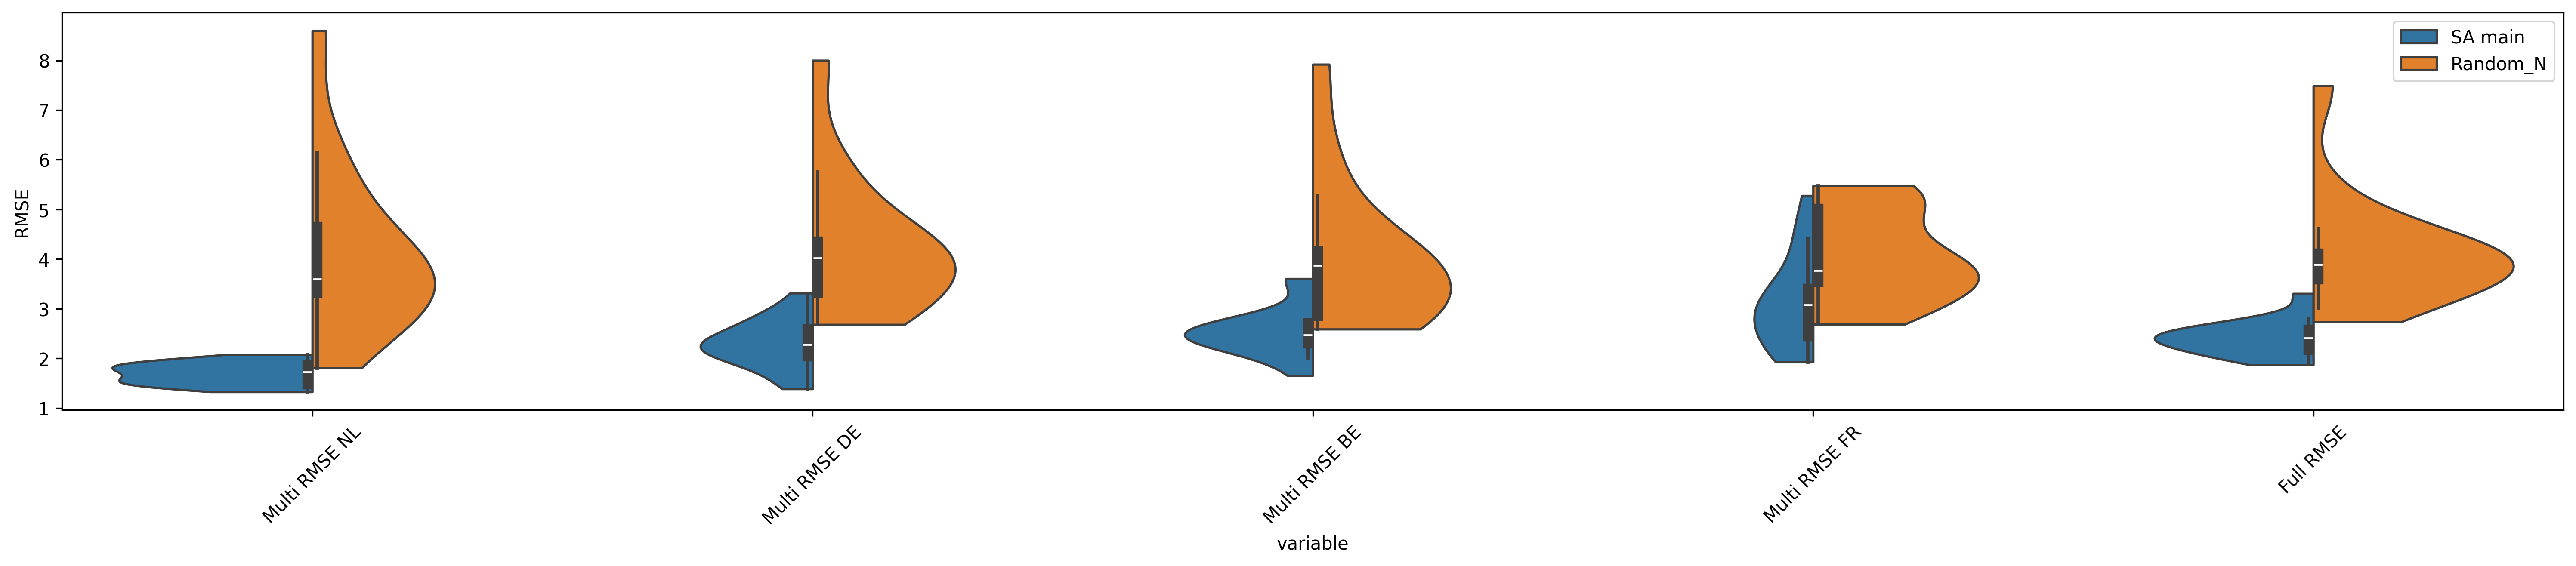

In [50]:
# violin plot comparing main SA vs random draw

fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=violin_data_sa_random,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)

# Add K_medoids RMSE as scatter points
k_medoids_metrics = df_multi_rmse[df_multi_rmse["dataset"] == "K_medoids_cf"]
for i, country in enumerate(COUNTRIES):
    k_medoids_rmse = k_medoids_metrics[
        k_medoids_metrics["variable"] == f"Multi RMSE {country}"
    ]["RMSE"].iloc[0]
    # ax.scatter(
    #     i,
    #     k_medoids_rmse,
    #     marker="x",
    #     color="red",
    #     s=100,
    #     linewidth=3,
    #     label="K_medoids" if i == 0 else "",
    #     zorder=10,
    # )

# ax.scatter(
#     i + 1,
#     k_medoids_metrics[k_medoids_metrics["variable"] == "Full RMSE"]["RMSE"].iloc[0],
#     marker="x",
#     color="red",
#     s=100,
#     linewidth=3,
#     zorder=10,
# )

ax.tick_params(axis="x", labelrotation=45)
# ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

In [49]:
df_multi_rmse[df_multi_rmse["dataset"] == "K_medoids_cf"]

,dataset,variable,MAE,RMSE,MaxAbs,Median of VAR,x_min,x_max
180,K_medoids_cf,Multi RMSE NL,NaN,2.379330,NaN,NaN,NaN,NaN
181,K_medoids_cf,Multi RMSE DE,NaN,2.142153,NaN,NaN,NaN,NaN
182,K_medoids_cf,Multi RMSE BE,NaN,2.016419,NaN,NaN,NaN,NaN
183,K_medoids_cf,Multi RMSE FR,NaN,2.774516,NaN,NaN,NaN,NaN
265,K_medoids_cf,Full RMSE,NaN,2.328105,NaN,NaN,NaN,NaN


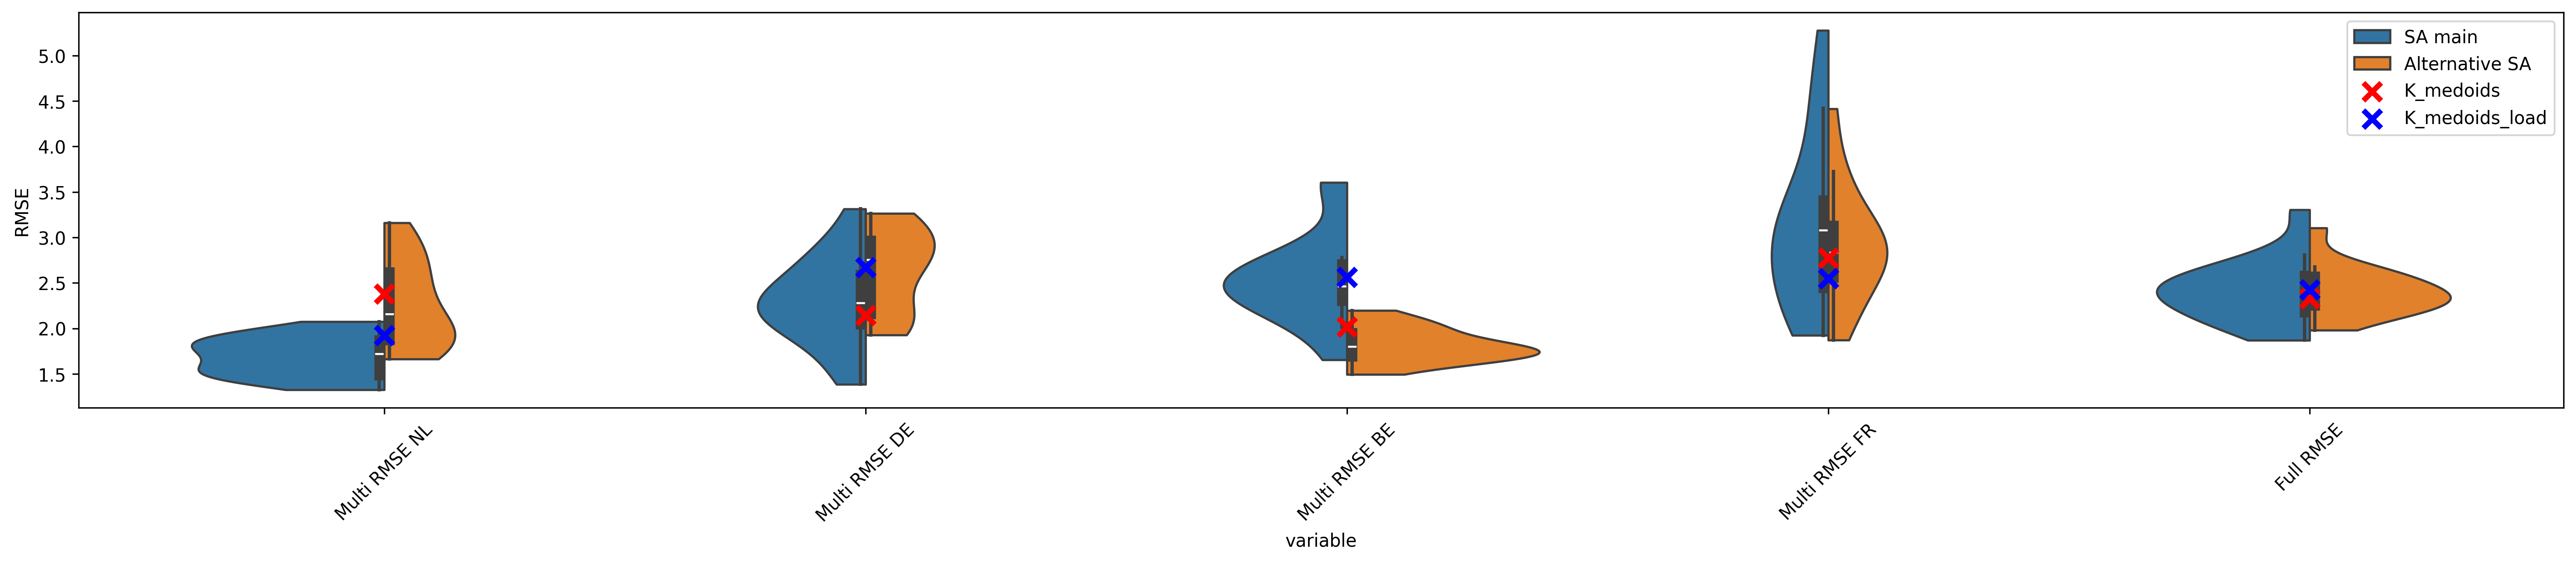

In [60]:
# violin with comparing two SA versions

fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=violin_data_sa,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)

# sns.violinplot(
#     data = random_metrics,
#     x = "variable",
#     y = "RMSE",
#     ax = ax,
#     color = "lightgrey",
#     cut = 0,
#     label = "Random"
# )

# Add K_medoids RMSE as scatter points
k_medoids_metrics = df_multi_rmse[df_multi_rmse["dataset"] == "K_medoids_cf"]
k_medoids_load = df_multi_rmse[df_multi_rmse["dataset"] == "K_medoids_load"]
for i, country in enumerate(COUNTRIES):
    k_medoids_rmse = k_medoids_metrics[
        k_medoids_metrics["variable"] == f"Multi RMSE {country}"
    ]["RMSE"].iloc[0]
    k_medoids_load_rmse = k_medoids_load[
        k_medoids_load["variable"] == f"Multi RMSE {country}"
    ]["RMSE"].iloc[0]
    ax.scatter(
        i,
        k_medoids_rmse,
        marker="x",
        color="red",
        s=100,
        linewidth=3,
        label="K_medoids" if i == 0 else "",
        zorder=10,
    )
    ax.scatter(
        i,
        k_medoids_load_rmse,
        marker="x",
        color="blue",
        s=100,
        linewidth=3,
        label="K_medoids_load" if i == 0 else "",
        zorder=10,
    )

ax.scatter(
    i + 1,
    k_medoids_metrics[k_medoids_metrics["variable"] == "Full RMSE"]["RMSE"].iloc[0],
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    zorder=10,
)

ax.scatter(
    i + 1,
    k_medoids_load[k_medoids_load["variable"] == "Full RMSE"]["RMSE"].iloc[0],
    marker="x",
    color="blue",
    s=100,
    linewidth=3,
    zorder=10,
)

ax.tick_params(axis="x", labelrotation=45)
# ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

In [55]:
# columns_with_multi = ["Residual_load", "NL_OFF_prod", "NL_ON_prod", "NL_SOLAR_prod", "Demand", "Multi RMSE"]
# columns_with_multi = np.append(multi_rmse_vars, "Multi RMSE")

# Get centroid RMSE values for each variable
centroid_metrics = df_metrics[df_metrics["dataset"].str.contains("Multi")].copy()
alternative_metrics = df_metrics[
    df_metrics["dataset"].str.contains("Alternative")
].copy()
# random_metrics = df_metrics_with_multi[df_metrics_with_multi['dataset'].str.contains('Random')].copy()
random_metrics = df_metrics[df_metrics["dataset"].str.contains("Random_N")].copy()
# Add dataset type column for grouping
centroid_metrics["dataset_type"] = "Simulated Annealing"
alternative_metrics["dataset_type"] = "Alternative SA"
random_metrics["dataset_type"] = "Random_N"
# Combine data for violin plot
violin_data_per_var = pd.concat([centroid_metrics, random_metrics])
violin_data_per_var_sa = pd.concat([centroid_metrics, alternative_metrics])

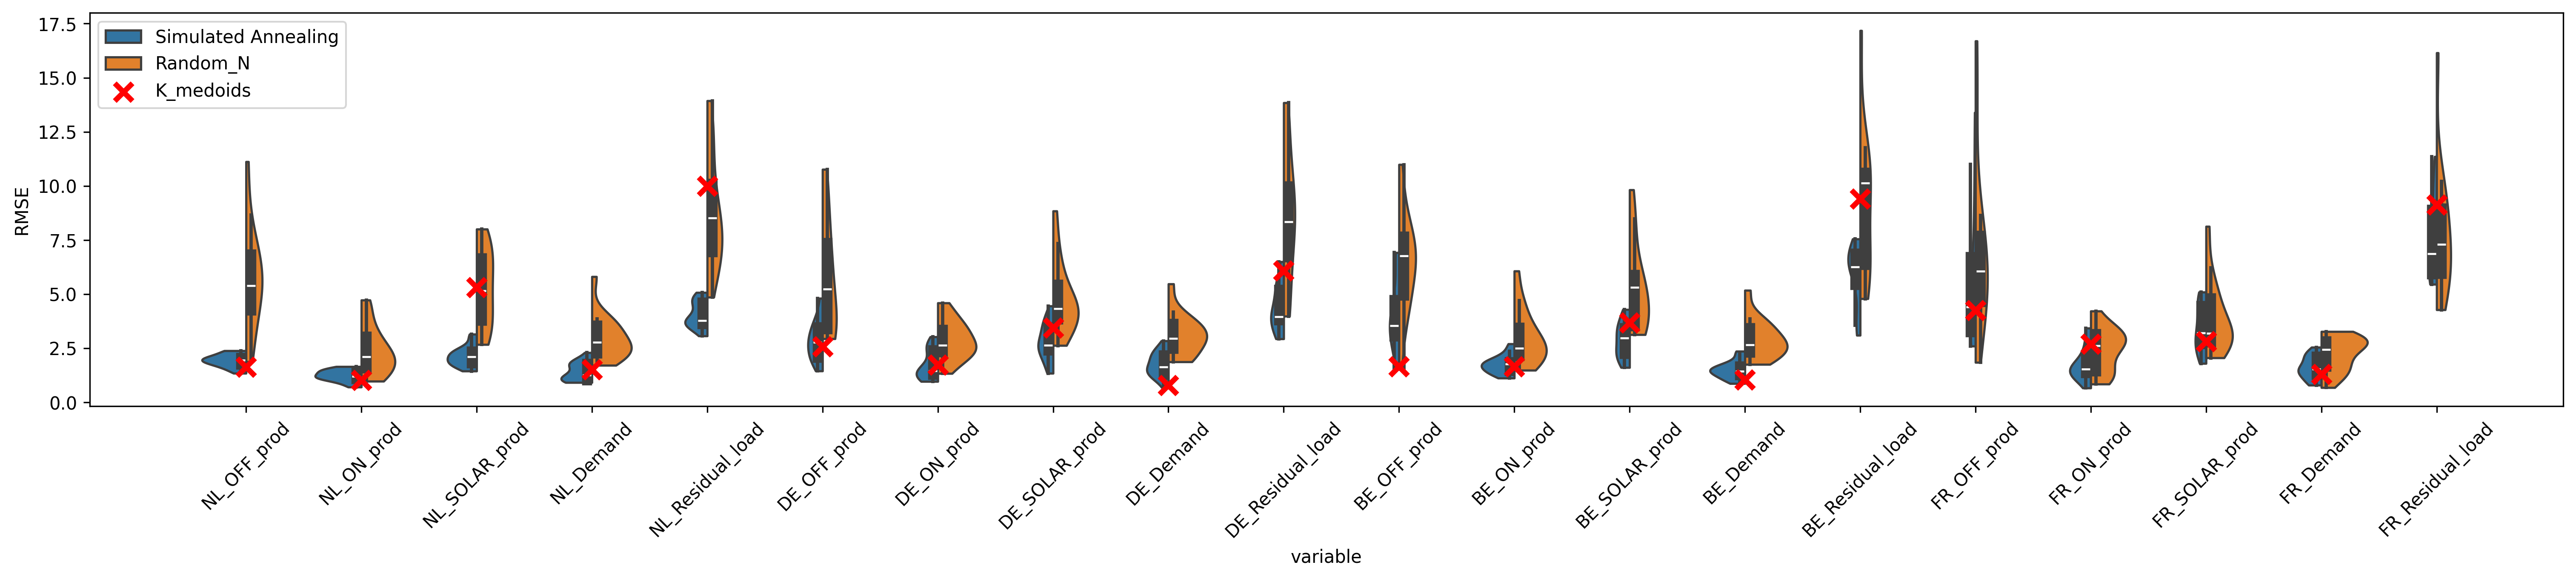

In [56]:
# Create violin plot of centroid RMSE values
fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=violin_data_per_var,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)

# Add K_medoids RMSE as scatter points
k_medoids_metrics = df_metrics_with_multi[
    df_metrics_with_multi["dataset"] == "K_medoids"
]
for i, var in enumerate(vars_to_standardize):
    k_medoids_rmse = k_medoids_metrics[k_medoids_metrics["variable"] == var][
        "RMSE"
    ].iloc[0]
    ax.scatter(
        i,
        k_medoids_rmse,
        marker="x",
        color="red",
        s=100,
        linewidth=3,
        label="K_medoids" if i == 0 else "",
        zorder=10,
    )
    # random_large_rmse = df_metrics_with_multi[df_metrics_with_multi['dataset'] == 'Large Random'][df_metrics_with_multi['variable'] == var]['RMSE'].iloc[0]
    # ax.scatter(i, random_large_rmse, marker='x', color='blue', s=100, linewidth=3, label='Large Random' if i == 0 else "", zorder = 10)

ax.tick_params(axis="x", labelrotation=45)
# ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

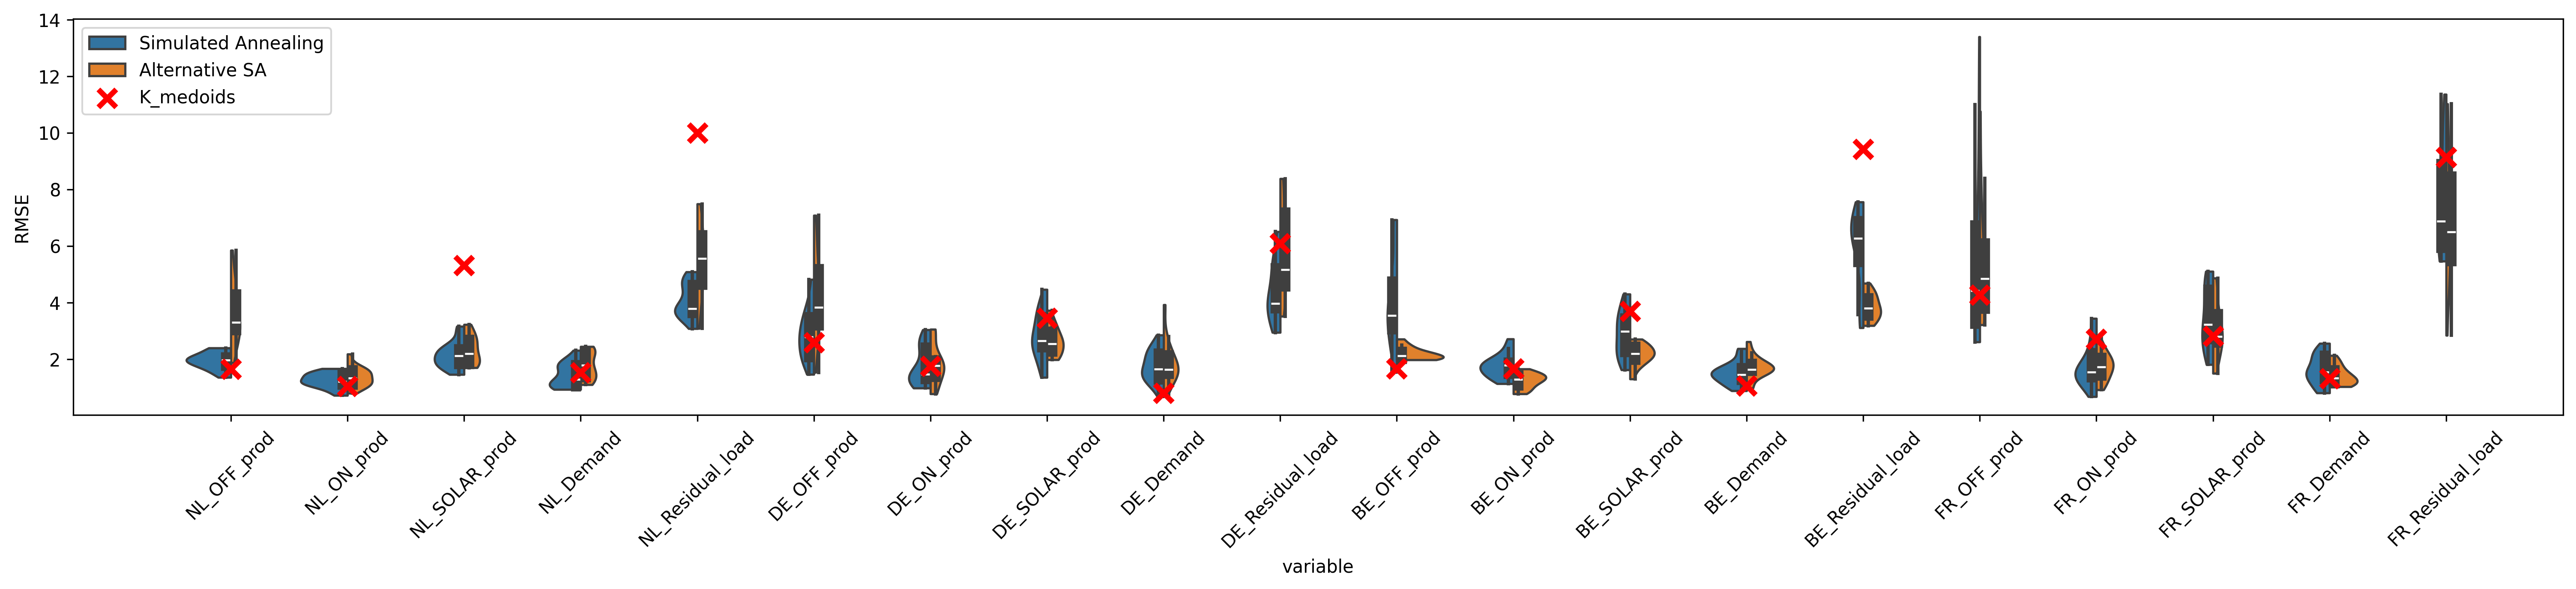

In [57]:
# Create violin plot of centroid RMSE values
fig, ax = plt.subplots(figsize=(25, 4), dpi=300)

# Create violin plot with split violins
sns.violinplot(
    data=violin_data_per_var_sa,
    x="variable",
    y="RMSE",
    hue="dataset_type",
    split=True,
    ax=ax,
    cut=0,
)

# Add K_medoids RMSE as scatter points
k_medoids_metrics = df_metrics_with_multi[
    df_metrics_with_multi["dataset"] == "K_medoids"
]
for i, var in enumerate(vars_to_standardize):
    k_medoids_rmse = k_medoids_metrics[k_medoids_metrics["variable"] == var][
        "RMSE"
    ].iloc[0]
    ax.scatter(
        i,
        k_medoids_rmse,
        marker="x",
        color="red",
        s=100,
        linewidth=3,
        label="K_medoids" if i == 0 else "",
        zorder=10,
    )
    # random_large_rmse = df_metrics_with_multi[df_metrics_with_multi['dataset'] == 'Large Random'][df_metrics_with_multi['variable'] == var]['RMSE'].iloc[0]
    # ax.scatter(i, random_large_rmse, marker='x', color='blue', s=100, linewidth=3, label='Large Random' if i == 0 else "", zorder = 10)

ax.tick_params(axis="x", labelrotation=45)
# ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

In [58]:
# compute Wasserstein
# TODO: make disjoint
ds_ref = df_daily[vars_to_match].to_numpy()

df_wasserstein = pd.DataFrame(index=datasets.keys(), columns=["Wasserstein_distance"])
for dataset in datasets:
    ds_sel = datasets[dataset][vars_to_match].to_numpy()
    df_wasserstein.loc[dataset, "Wasserstein_distance"] = sliced_wasserstein_distance(
        ds_sel, ds_ref, seed=seed, n_projections=50
    )

In [59]:
# Get centroid RMSE values for each variable
centroid_wasserstein = df_wasserstein[df_wasserstein.index.str.contains("Multi")].copy()
alternative_wasserstein = df_wasserstein[
    df_wasserstein.index.str.contains("Alternative")
].copy()
# random_metrics
random_wasserstein = df_wasserstein[
    df_wasserstein.index.str.contains("Random_N")
].copy()

large_random_wasserstein = df_wasserstein[
    df_wasserstein.index.str.contains("Large Random")
].copy()

# Add dataset type column for grouping
random_wasserstein["dataset_type"] = "Random_N"
centroid_wasserstein["dataset_type"] = "SA main"
alternative_wasserstein["dataset_type"] = "Alternative SA"
large_random_wasserstein["dataset_type"] = "Large Random"

# Combine data for violin plot
violin_data_wasserstein = pd.concat([centroid_wasserstein, random_wasserstein])
violin_data_wasserstein.reset_index(inplace=True)
violin_data_wasserstein.rename(columns={"index": "dataset"}, inplace=True)

violin_data_wasserstein_sa = pd.concat([centroid_wasserstein, alternative_wasserstein])
violin_data_wasserstein_sa.reset_index(inplace=True)
violin_data_wasserstein_sa.rename(columns={"index": "dataset"}, inplace=True)

(0.0, 10.0)

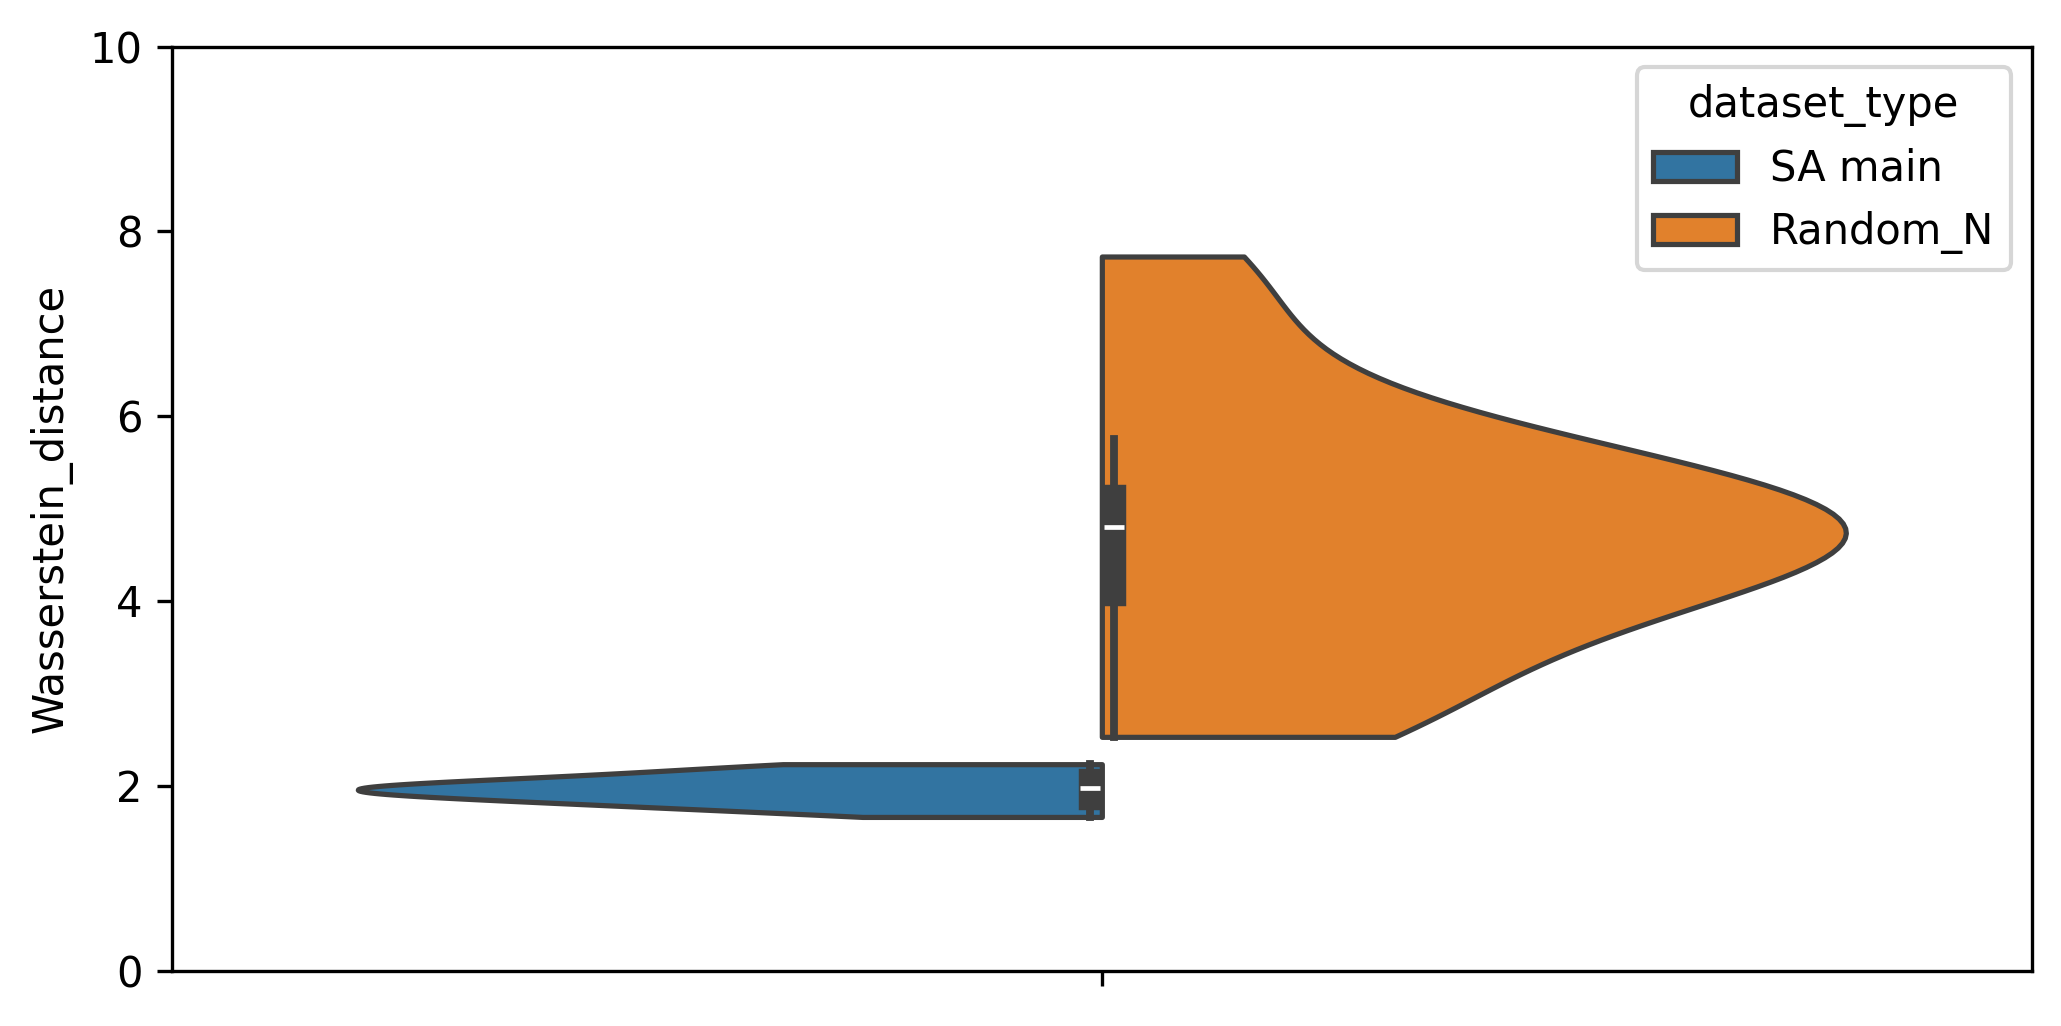

In [60]:
# main SA vs random

fig, ax = plt.subplots(figsize=(8, 4), dpi=300)
# Create violin plot with split violins
sns.violinplot(
    data=violin_data_wasserstein,
    hue="dataset_type",
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)
# Add K_medoids RMSE as scatter points
k_medoids_wasserstein = df_wasserstein.loc["K_medoids", "Wasserstein_distance"]
# ax.scatter(
#     0,
#     k_medoids_wasserstein,
#     marker="x",
#     color="red",
#     s=100,
#     linewidth=3,
#     label="K_medoids",
#     zorder=10,
# )

ax.set_ylim(0, 10)

(0.0, 10.0)

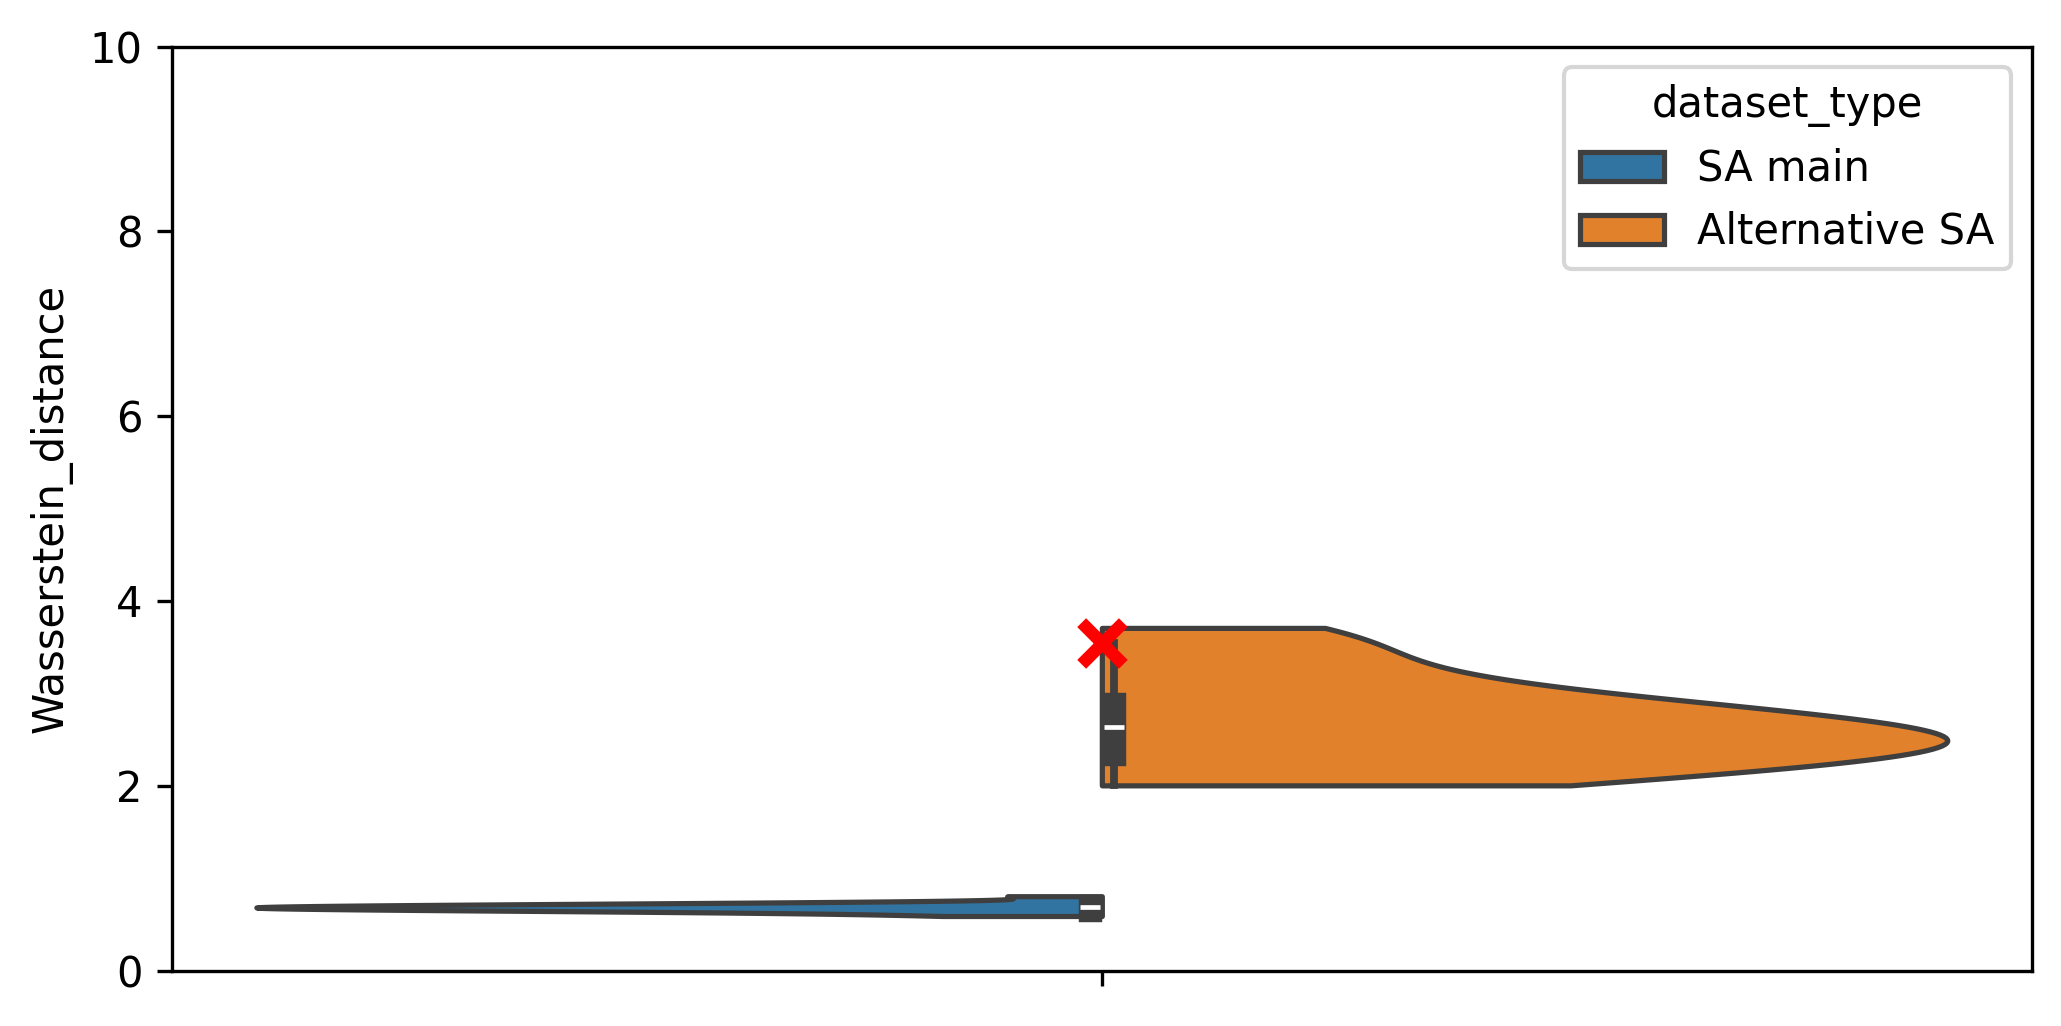

In [20]:
# main SA vs alternative SA
fig, ax = plt.subplots(figsize=(8, 4), dpi=300)
# Create violin plot with split violins
sns.violinplot(
    data=violin_data_wasserstein_sa,
    hue="dataset_type",
    y="Wasserstein_distance",
    ax=ax,
    cut=0,
    split=True,
)
# Add K_medoids RMSE as scatter points
k_medoids_wasserstein = df_wasserstein.loc["K_medoids", "Wasserstein_distance"]
ax.scatter(
    0,
    k_medoids_wasserstein,
    marker="x",
    color="red",
    s=100,
    linewidth=3,
    label="K_medoids",
    zorder=10,
)

ax.set_ylim(0, 10)

In [21]:
# calculate large random scores

# Get centroid RMSE values for each variable
random_metrics_lr = df_metrics_with_multi[
    df_metrics_with_multi["dataset"].str.contains("Large Random")
].copy()
# Add dataset type column for grouping
# random_metrics['dataset_type'] = 'Random'
random_metrics_lr["dataset_type"] = "Large Random"

for size in sizes:
    multi_rmse_lr = random_metrics_lr[
        random_metrics_lr["dataset"].str.contains(f"Large Random {size}")
    ]["RMSE"]

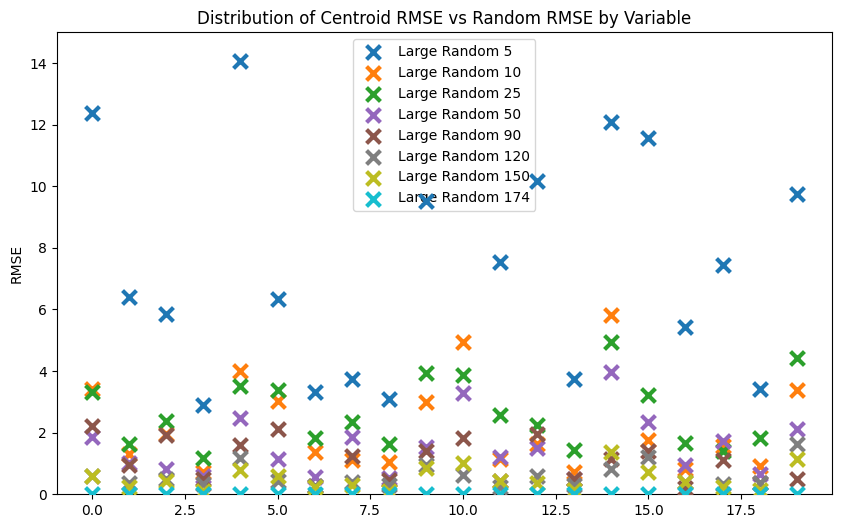

In [22]:
# Create violin plot of centroid RMSE values
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.tab10(np.linspace(0, 1, len(sizes)))
for i, var in enumerate(vars_to_standardize):
    for j, size in enumerate(sizes):
        rmse = random_metrics_lr.query(
            f"dataset == 'Large Random {size}' and variable == @var"
        )["RMSE"].item()
        ax.scatter(
            i,
            rmse,
            marker="x",
            s=100,
            linewidth=3,
            label=f"Large Random {size}" if i == 0 else "",
            zorder=10,
            color=colors[j],
        )

ax.set_ylim(0, 15)
ax.set_title("Distribution of Centroid RMSE vs Random RMSE by Variable")
ax.set_ylabel("RMSE")
ax.legend()

# 3. Look at longer-events (non-optimized)

In [ ]:
ecdf_comparison(
    df_daily[columns_plot].rolling(window=7).mean(),
    df_centroids[columns_plot].rolling(window=7).mean(),
    df_random[columns_plot].rolling(window=7).mean(),
    columns_plot,
)
qq_compute_metrics(
    df_daily[columns_plot].rolling(window=7).mean(),
    {
        "Centroid": df_centroids[columns_plot].rolling(window=7).mean(),
        "Random": df_random[columns_plot].rolling(window=7).mean(),
    },
    columns_plot,
)
qq_plot(
    df_daily[columns_plot].rolling(window=7).mean(),
    {
        "Centroid": df_centroids[columns_plot].rolling(window=7).mean(),
        "Random": df_random[columns_plot].rolling(window=7).mean(),
    },
    columns_plot,
)

NameError: name 'df_random' is not defined